# 06_01 Estimation: Method of Moments and Maximum Likelihood

**Learning objectives**
- Judge an **estimator** by its **bias, variance and mean squared error**, and know what **consistency** and **efficiency** mean.
- Build estimators by the **method of moments** (match sample and theoretical moments) and by **maximum likelihood** (choose the parameter that makes the data most probable).
- Compute the **Fisher information**, the **standard error** of an MLE and the **Cramer-Rao bound**.
- See the **likelihood surface** in 2D and 3D, and meet a case where the MLE is *not* Normal and is biased (the German tank problem).

**Prerequisites:** [00_02 Expectation and moments](../../module_00_foundations/notebooks/00_02_expectation_moments.ipynb), [05_02 The central limit theorem](../../module_05_sampling/notebooks/05_02_central_limit_theorem.ipynb), [05_06 Delta method and Slutsky](../../module_05_sampling/notebooks/05_06_delta_method_slutsky.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math
from scipy import optimize, special

## 2. Prerequisite recap

- A **parameter** $\theta$ is a fixed unknown number describing a distribution (a rate $\lambda$, a mean $\mu$); an **estimator** $\hat\theta=T(X_1,\dots,X_n)$ is a function of the data, so it is a random variable with its own **sampling distribution** (05_03).
- **Expectation, variance and moments:** $E[X]$, $\mathrm{Var}(X)$, $E[X^k]$ (00_02). For iid data the sample mean has $\mathrm{Var}(\bar X)=\sigma^2/n$.
- **Likelihood of independent data** is a product of densities; its logarithm is a sum (which is much easier to differentiate).
- **The CLT and the delta method** (05_02, 05_06) say that smooth functions of averages are approximately Normal.

## 3. Intuition and story

We have a sample and a model family, for example "component lifetimes follow an Exponential distribution", but the **parameter is unknown**. Estimation is the art of turning data into the best single guess for it, together with an idea of how wrong the guess may be.

Two natural recipes:

1. **Method of moments (MoM):** a model has theoretical averages that depend on the parameter ($E[X]=1/\lambda$ for the Exponential). Replace the theoretical average by the sample average and solve for the parameter. It is quick and always gives something.
2. **Maximum likelihood (MLE):** write the probability (density) of the data you actually saw *as a function of the parameter* and pick the parameter value that makes the data **most probable**. It is the workhorse of statistics and machine learning (training a classifier by cross-entropy *is* maximum likelihood).

Neither recipe is perfect for small samples (they can be biased), but the MLE is **asymptotically the best possible** among reasonable estimators: for large $n$ it is unbiased, Normal, and has the smallest possible variance.

## 4. Formal definitions

| Term | Definition |
|---|---|
| **Estimator** | a rule $\hat\theta=T(X_1,\dots,X_n)$; the number it gives for one sample is the **estimate** |
| **Bias** | $\mathrm{Bias}(\hat\theta)=E[\hat\theta]-\theta$; **unbiased** if it is 0 |
| **Variance, standard error** | $\mathrm{Var}(\hat\theta)$; $\mathrm{SE}(\hat\theta)=\sqrt{\mathrm{Var}(\hat\theta)}$ |
| **Mean squared error** | $\mathrm{MSE}=E[(\hat\theta-\theta)^2]=\mathrm{Var}(\hat\theta)+\mathrm{Bias}(\hat\theta)^2$ |
| **Consistent** | $\hat\theta_n\to\theta$ in probability as $n\to\infty$ |
| **Method of moments** | solve $E_\theta[X^j]=\frac1n\sum X_i^j$ for $j=1,\dots,p$ ($p$ parameters) |
| **Likelihood** | $L(\theta)=\prod_{i=1}^nf(x_i;\theta)$; **log-likelihood** $\ell(\theta)=\sum\ln f(x_i;\theta)$ |
| **MLE** | $\hat\theta_{ML}=\arg\max_\theta\ell(\theta)$; solves the **score equation** $\ell'(\theta)=0$ |
| **Fisher information** | $I(\theta)=-E[\ell''_1(\theta)]=E[(\ell_1'(\theta))^2]$ for one observation; $nI(\theta)$ for $n$ |
| **Asymptotics of the MLE** | $\sqrt n(\hat\theta_{ML}-\theta)\to N\big(0,\,1/I(\theta)\big)$ |
| **Cramer-Rao bound** | any unbiased estimator has $\mathrm{Var}(\hat\theta)\ge\dfrac1{nI(\theta)}$ |
| **Invariance** | the MLE of $g(\theta)$ is $g(\hat\theta_{ML})$ |

## 5. Derivations

### 5.1 Bias-variance decomposition of the MSE
Write $\hat\theta-\theta=(\hat\theta-E\hat\theta)+(E\hat\theta-\theta)$ and square: the cross term has mean 0, so $\mathrm{MSE}=\mathrm{Var}(\hat\theta)+\mathrm{Bias}^2$. **In plain words.** An estimator can miss the target because it is *shaky* (variance) or because it is *aimed at the wrong place* (bias); a slightly biased but very steady estimator can beat an unbiased wobbly one.

### 5.2 MLE of the Exponential rate
For $f(x;\lambda)=\lambda e^{-\lambda x}$: $\ell(\lambda)=n\ln\lambda-\lambda\sum x_i$. Setting $\ell'(\lambda)=n/\lambda-\sum x_i=0$ gives $\hat\lambda=n/\sum x_i=1/\bar x$. The second derivative is $-n/\lambda^2<0$, so it is a maximum, and the Fisher information is $I(\lambda)=1/\lambda^2$, hence $\mathrm{SE}(\hat\lambda)\approx\lambda/\sqrt n$. The method of moments gives the same estimate here because $E[X]=1/\lambda$. **In plain words.** The best rate is the number of events divided by the total observation time.

### 5.3 The MLE can be biased in small samples
$\sum X_i\sim\text{Gamma}(n,\text{rate }\lambda)$, and $E[1/\sum X_i]=\lambda/(n-1)$, so $E[\hat\lambda]=\dfrac n{n-1}\lambda$: the MLE overestimates the rate by the factor $n/(n-1)$ (5 % for $n=21$). The estimator $\tilde\lambda=\dfrac{n-1}{n}\hat\lambda$ is unbiased. **In plain words.** Because $1/x$ is a curved (convex) function, the average of $1/\bar x$ is above $1/E\bar x$ (Jensen's inequality); the bias shrinks like $1/n$ and disappears for large samples.

### 5.4 MLE for the Normal distribution
$\ell(\mu,\sigma^2)=-\frac n2\ln(2\pi\sigma^2)-\frac1{2\sigma^2}\sum(x_i-\mu)^2$. Setting the two partial derivatives to 0 gives $\hat\mu=\bar x$ and $\hat\sigma^2=\frac1n\sum(x_i-\bar x)^2$. The latter has $E[\hat\sigma^2]=\frac{n-1}n\sigma^2$: biased low, which is why the sample variance divides by $n-1$ (05_03). **In plain words.** Distances are measured from $\bar x$, which sits in the middle of the data, so they are on average a little too small.

### 5.5 Fisher information and the Cramer-Rao bound
The information measures how sharply the log-likelihood peaks: a sharp peak means the data pin $\theta$ down, a flat one means they do not. The Cramer-Rao bound $\mathrm{Var}(\hat\theta)\ge1/(nI(\theta))$ says no unbiased estimator can be steadier than the MLE's asymptotic variance. **In plain words.** The curvature of the log-likelihood at its top *is* the information, and the standard error is one over the square root of the total information.

### 5.6 Invariance
If $\hat\lambda$ maximises the likelihood in $\lambda$, then $g(\hat\lambda)$ maximises it in the new parameter $g(\lambda)$, because reparametrising only relabels the points of the likelihood curve. The delta method (05_06) gives the standard error: $\mathrm{SE}(g(\hat\lambda))\approx|g'(\lambda)|\,\mathrm{SE}(\hat\lambda)$. **In plain words.** The best estimate of the survival chance $e^{-200\lambda}$ is $e^{-200\hat\lambda}$: plug the estimate in.

### 5.7 When the regularity conditions fail: Uniform$(0,\theta)$
The likelihood is $\theta^{-n}$ for $\theta\ge\max x_i$ and 0 otherwise, so it *increases* until $\theta=\max x_i$ and then drops to zero: $\hat\theta_{ML}=\max x_i$ (no derivative is zero). Since $\max x_i<\theta$ always, the MLE is biased low, with $E[\max]=\frac n{n+1}\theta$, and its error shrinks like $1/n$, not $1/\sqrt n$. **In plain words.** The largest observation can never exceed the true maximum, so it systematically underestimates it.

## 6. Properties and relationships

- **MoM versus ML:** often identical (Exponential, Normal mean); when they differ the MLE is usually the more precise (Example 2).
- **Large-sample optimality:** the MLE is consistent, asymptotically Normal and attains the Cramer-Rao bound; confidence intervals follow (06_02), as do likelihood-ratio tests (06_03).
- **Bias is not the whole story:** the MSE trades bias against variance (Example 3: a biased estimator with smaller MSE).
- **Link to ML and AI:** minimising the squared error of a linear model with Normal noise, or the cross-entropy of a classifier, **is** maximum likelihood; regularisation corresponds to a prior (Module 07).
- **Link to Module 05:** the standard error of the MLE is the delta-method / Fisher-information standard error; the bootstrap (05_04) gives an alternative when formulas are awkward.

## 7. 2D visuals

### 7.1 The log-likelihood curve of the Exponential rate
For 30 component lifetimes (sum 4,872 hours) the log-likelihood $\ell(\lambda)=30\ln\lambda-4872\lambda$ peaks at $\hat\lambda=30/4872=0.00616$. The curvature at the peak gives the standard error.

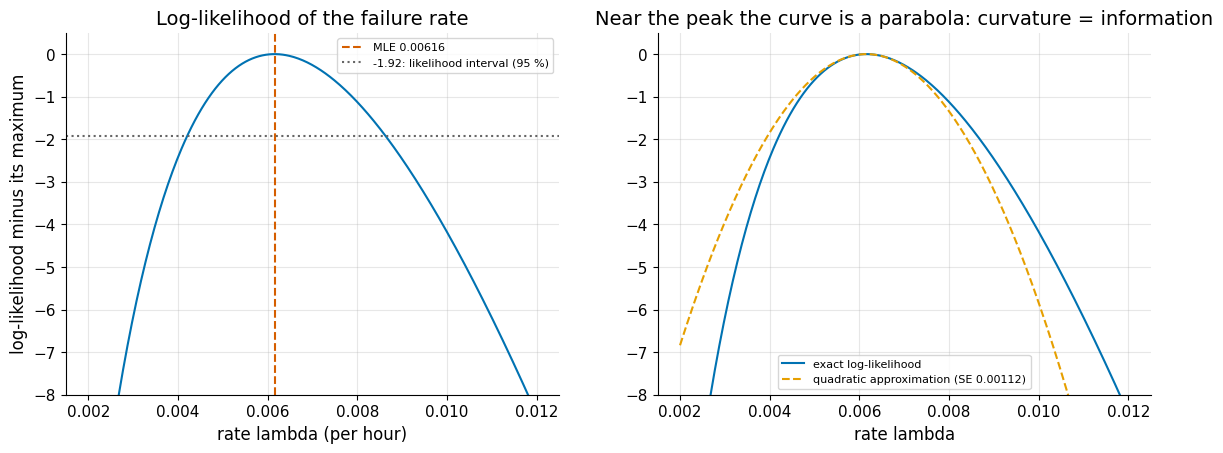

In [2]:
n_main, sum_main = 30, 4872.0; xbar_main = sum_main / n_main
lam_hat = n_main / sum_main
lam_grid = np.linspace(0.002, 0.012, 400)
ll_main = n_main * np.log(lam_grid) - lam_grid * sum_main
se_fisher = lam_hat / np.sqrt(n_main)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.7))
axes[0].plot(lam_grid, ll_main - ll_main.max(), color=MAIN); axes[0].axvline(lam_hat, color=HIGHLIGHT, linestyle="--", label=f"MLE {lam_hat:.5f}")
axes[0].axhline(-1.92, color=NEUTRAL, linestyle=":", label="-1.92: likelihood interval (95 %)"); axes[0].set_ylim(-8, 0.5); axes[0].set_xlabel("rate lambda (per hour)"); axes[0].set_ylabel("log-likelihood minus its maximum"); axes[0].set_title("Log-likelihood of the failure rate"); axes[0].legend(fontsize=8)
quad = -0.5 * ((lam_grid - lam_hat) / se_fisher) ** 2
axes[1].plot(lam_grid, ll_main - ll_main.max(), color=MAIN, label="exact log-likelihood"); axes[1].plot(lam_grid, quad, color=SIM, linestyle="--", label=f"quadratic approximation (SE {se_fisher:.5f})")
axes[1].set_ylim(-8, 0.5); axes[1].set_xlabel("rate lambda"); axes[1].set_title("Near the peak the curve is a parabola: curvature = information"); axes[1].legend(fontsize=8)
plt.show()
assert np.isclose(lam_grid[np.argmax(ll_main)], lam_hat, atol=2.5e-5)

### 7.2 Estimators have their own sampling distribution
10,000 samples of $n=30$ Exponential lifetimes (true mean 160 h, rate 0.00625). The histogram of the MLE $\hat\lambda=1/\bar x$ is slightly skewed and centred a little **above** the truth (bias factor $n/(n-1)=1.034$); the bias-corrected estimator is centred on the truth.

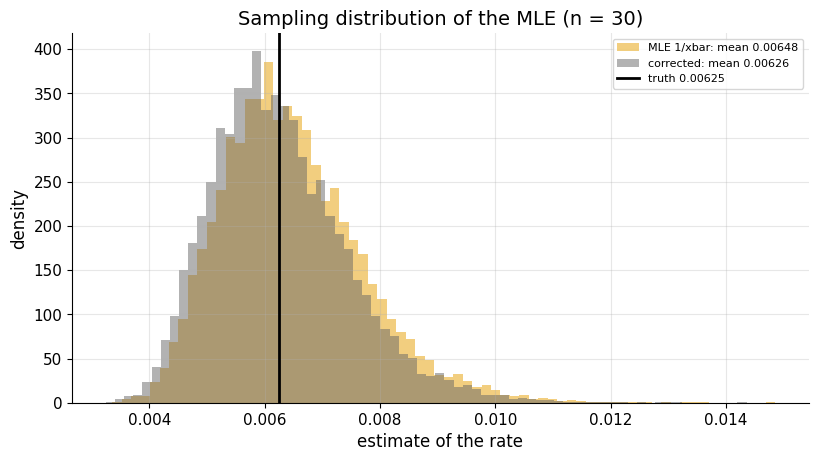

bias of the MLE: +3.63% (theory +3.45%) | SD of the MLE 0.00123 vs asymptotic SE 0.00114


In [3]:
true_lam = 1 / 160.0
sample_mat = rng.exponential(160.0, (10_000, 30))
mle_vals = 1 / sample_mat.mean(axis=1); unb_vals = (29 / 30) * mle_vals
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hist(mle_vals, bins=70, density=True, color=SIM, alpha=0.5, label=f"MLE 1/xbar: mean {mle_vals.mean():.5f}"); ax.hist(unb_vals, bins=70, density=True, color=NEUTRAL, alpha=0.5, label=f"corrected: mean {unb_vals.mean():.5f}")
ax.axvline(true_lam, color="black", linewidth=2, label=f"truth {true_lam:.5f}"); ax.set_xlabel("estimate of the rate"); ax.set_ylabel("density"); ax.set_title("Sampling distribution of the MLE (n = 30)"); ax.legend(fontsize=8)
plt.show()
print(f"bias of the MLE: {mle_vals.mean() / true_lam - 1:+.2%} (theory +{30 / 29 - 1:.2%}) | SD of the MLE {mle_vals.std():.5f} vs asymptotic SE {true_lam / np.sqrt(30):.5f}")
assert abs(mle_vals.mean() / true_lam - 30 / 29) < 0.01 and abs(unb_vals.mean() / true_lam - 1) < 0.01

### 7.3 Bias, variance and MSE as the sample grows
The MSE of the MLE and of the corrected estimator against $n$: both go to zero (consistency), the corrected one is slightly better at very small $n$ in bias but not always in MSE.

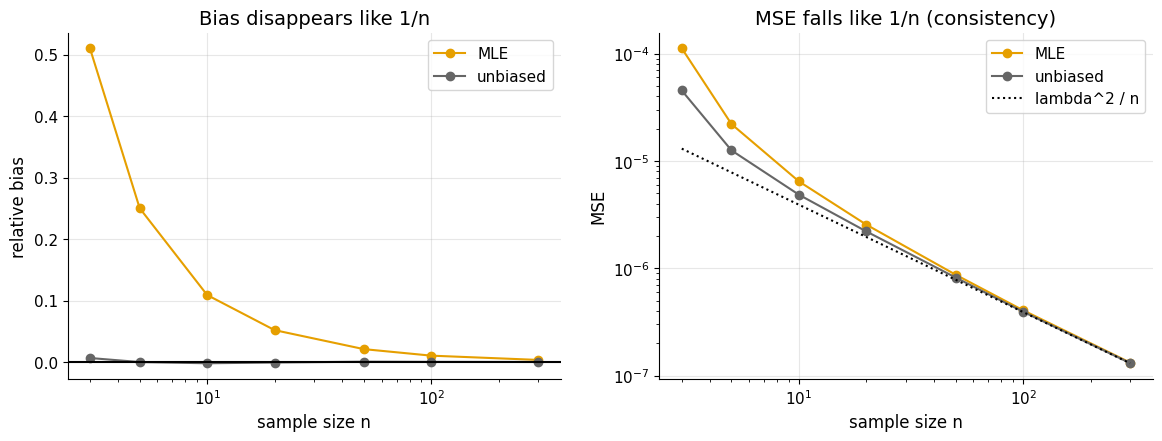

  n estimator      bias     variance          MSE
  5       MLE  0.001564 1.960000e-05 2.205000e-05
  5  unbiased  0.000001 1.254000e-05 1.254000e-05
 20       MLE  0.000326 2.440000e-06 2.540000e-06
 20  unbiased -0.000003 2.200000e-06 2.200000e-06
300       MLE  0.000023 1.300000e-07 1.300000e-07
300  unbiased  0.000002 1.300000e-07 1.300000e-07


In [4]:
ns = [3, 5, 10, 20, 50, 100, 300]
rows = []
for nn in ns:
    m_ = 1 / rng.exponential(160.0, (20_000, nn)).mean(axis=1)
    for name, est in [("MLE", m_), ("unbiased", (nn - 1) / nn * m_)]:
        rows.append({"n": nn, "estimator": name, "bias": est.mean() - true_lam, "variance": est.var(), "MSE": np.mean((est - true_lam) ** 2)})
bv = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, c in [("MLE", SIM), ("unbiased", NEUTRAL)]:
    d = bv[bv.estimator == name]; axes[0].plot(d.n, d.bias / true_lam, "o-", color=c, label=name); axes[1].loglog(d.n, d.MSE, "o-", color=c, label=name)
axes[0].axhline(0, color="black"); axes[0].set_xscale("log"); axes[0].set_xlabel("sample size n"); axes[0].set_ylabel("relative bias"); axes[0].set_title("Bias disappears like 1/n"); axes[0].legend()
axes[1].loglog(ns, (true_lam ** 2) / np.array(ns), "k:", label="lambda^2 / n"); axes[1].set_xlabel("sample size n"); axes[1].set_ylabel("MSE"); axes[1].set_title("MSE falls like 1/n (consistency)"); axes[1].legend()
plt.show()
print(bv[bv.n.isin([5, 30 if 30 in ns else 20, 300])].round(8).to_string(index=False))
assert bv[(bv.estimator == "MLE") & (bv.n == 300)].MSE.iloc[0] < bv[(bv.estimator == "MLE") & (bv.n == 10)].MSE.iloc[0] / 10

### 7.4 Log-likelihood of a Normal sample as a contour map
Contours of $\ell(\mu,\sigma)$ for 25 measurements: the peak is at $(\bar x,\hat\sigma)$ and the shape is elongated in the $\sigma$ direction because the data pin the mean down better than the spread.

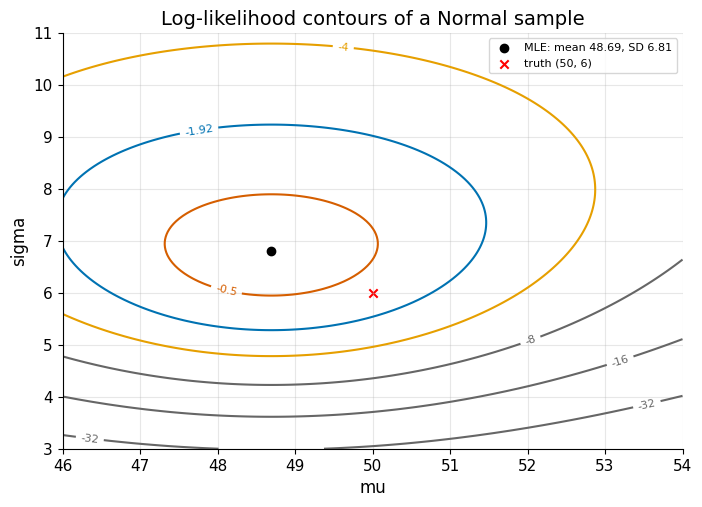

In [5]:
meas = rng.normal(50, 6, 25)
mu_g = np.linspace(46, 54, 160); sg_g = np.linspace(3, 11, 160)
MU, SG = np.meshgrid(mu_g, sg_g)
LL = np.array([[stats.norm(m_, s_).logpdf(meas).sum() for m_ in mu_g] for s_ in sg_g])
mu_hat, sg_hat = meas.mean(), meas.std()                  # std with ddof = 0 is the MLE
fig, ax = plt.subplots(figsize=(8, 5.4))
cs = ax.contour(MU, SG, LL - LL.max(), levels=[-32, -16, -8, -4, -1.92, -0.5], colors=[NEUTRAL, NEUTRAL, NEUTRAL, SIM, MAIN, HIGHLIGHT])
ax.clabel(cs, fmt="%g", fontsize=8); ax.scatter([mu_hat], [sg_hat], color="black", zorder=3, label=f"MLE: mean {mu_hat:.2f}, SD {sg_hat:.2f}"); ax.scatter([50], [6], marker="x", color="red", label="truth (50, 6)")
ax.set_xlabel("mu"); ax.set_ylabel("sigma"); ax.set_title("Log-likelihood contours of a Normal sample"); ax.legend(fontsize=8)
plt.show()
assert abs(LL.argmax() // 160 - np.argmin(np.abs(sg_g - sg_hat))) <= 2

## 8. 3D visuals

### 8.1 Static: the log-likelihood surface
The same function as a surface over $(\mu,\sigma)$: a single smooth peak (a "hill"), steeper along $\mu$ than along $\sigma$. Maximum likelihood is *finding the top of this hill*; the curvature at the top gives the standard errors.

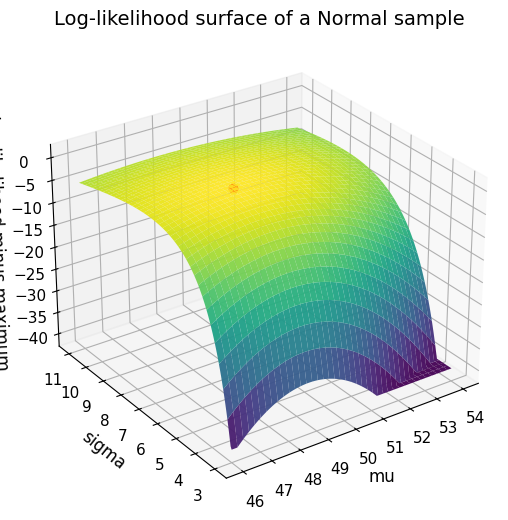

In [6]:
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
Zs = np.clip(LL - LL.max(), -40, 0)
ax.plot_surface(MU, SG, Zs, cmap="viridis", edgecolor="none", alpha=0.95)
ax.scatter([mu_hat], [sg_hat], [0], color="red", s=40)
ax.set_xlabel("mu"); ax.set_ylabel("sigma"); ax.set_zlabel("log-likelihood minus maximum"); ax.set_title("Log-likelihood surface of a Normal sample"); ax.view_init(elev=28, azim=-125)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Rotate the hill and hover to read the log-likelihood.

In [7]:
fig = go.Figure(go.Surface(x=mu_g, y=sg_g, z=Zs, colorscale="Viridis"))
fig.update_layout(title="Log-likelihood of a Normal sample", width=760, height=560, scene=dict(xaxis_title="mu", yaxis_title="sigma", zaxis_title="log-likelihood - max"))
fig.show()

### 8.3 Static: the Gamma log-likelihood over (shape, scale)
For 80 rainfall amounts the Gamma log-likelihood is a **banana-shaped** ridge: shape and scale trade off against each other because their product is pinned down by the mean. Strong correlation between parameters makes the estimates less precise.

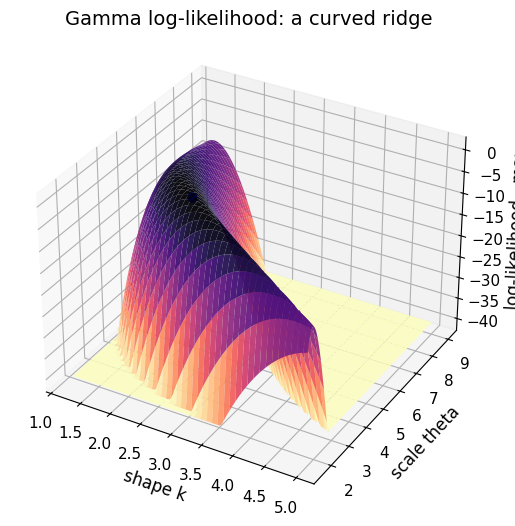

MLE: shape 2.609, scale 3.564 (truth 2.5 and 4.0); product k x theta = 9.300 = sample mean 9.300


In [8]:
rain = rng.gamma(2.5, 4.0, 80)
k_g = np.linspace(1.2, 5.0, 120); th_g = np.linspace(1.6, 9.0, 120)
Kg, Tg = np.meshgrid(k_g, th_g)
LLg = np.array([[stats.gamma(a=k_, scale=t_).logpdf(rain).sum() for k_ in k_g] for t_ in th_g])
fit_k, _, fit_th = stats.gamma.fit(rain, floc=0)
fig = plt.figure(figsize=(8.8, 6.2))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Kg, Tg, np.clip(LLg - LLg.max(), -40, 0), cmap="magma_r", edgecolor="none", alpha=0.95)
ax.scatter([fit_k], [fit_th], [0], color="blue", s=40); ax.set_xlabel("shape k"); ax.set_ylabel("scale theta"); ax.set_zlabel("log-likelihood - max"); ax.set_title("Gamma log-likelihood: a curved ridge"); ax.view_init(elev=32, azim=-60)
plt.show()
print(f"MLE: shape {fit_k:.3f}, scale {fit_th:.3f} (truth 2.5 and 4.0); product k x theta = {fit_k * fit_th:.3f} = sample mean {rain.mean():.3f}")
assert abs(fit_k * fit_th - rain.mean()) < 0.05

## 9. Simulation vs theory

### 9.1 The MLE is asymptotically Normal with the Fisher-information variance
For Exponential data the theory says $\hat\lambda\approx N\big(\lambda,\lambda^2/n\big)$. We compare the simulated distribution of $\sqrt n(\hat\lambda-\lambda)/\lambda$ with the standard Normal for $n=10,50,500$ (a Kolmogorov distance).

In [9]:
rows = []
for nn in [10, 50, 500]:
    est = 1 / rng.exponential(160.0, (20_000, nn)).mean(axis=1)
    z = np.sqrt(nn) * (est - true_lam) / true_lam
    rows.append({"n": nn, "mean of z": z.mean(), "SD of z (theory 1)": z.std(), "skewness": stats.skew(z), "KS distance to N(0,1)": stats.kstest(z, "norm").statistic})
asy = pd.DataFrame(rows); print(asy.round(4).to_string(index=False))
assert asy["KS distance to N(0,1)"].iloc[-1] < asy["KS distance to N(0,1)"].iloc[0] and abs(asy["SD of z (theory 1)"].iloc[-1] - 1) < 0.03

  n  mean of z  SD of z (theory 1)  skewness  KS distance to N(0,1)
 10     0.3720              1.2628    1.6730                 0.0854
 50     0.1409              1.0356    0.5691                 0.0373
500     0.0442              1.0164    0.2108                 0.0137


### 9.2 The Cramer-Rao bound: nothing beats $1/(nI)$
For the Normal mean $I=1/\sigma^2$ so the bound is $\sigma^2/n$; the sample mean attains it, the sample median does not (variance about $\frac\pi2\sigma^2/n$).

In [10]:
nn = 101
samples = rng.normal(0, 1, (40_000, nn))
v_mean, v_med = samples.mean(axis=1).var(), np.median(samples, axis=1).var()
print(f"variance of the mean {v_mean:.5f} (bound 1/n = {1 / nn:.5f}) | variance of the median {v_med:.5f} (theory pi/(2n) = {np.pi / (2 * nn):.5f}) | efficiency of the median {v_mean / v_med:.3f} (2/pi = {2 / np.pi:.3f})")
assert abs(v_mean * nn - 1) < 0.03 and abs(v_med * nn - np.pi / 2) < 0.06

variance of the mean 0.00985 (bound 1/n = 0.00990) | variance of the median 0.01548 (theory pi/(2n) = 0.01555) | efficiency of the median 0.636 (2/pi = 0.637)


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [11]:
data = rng.exponential(160.0, 40)
loc_e, scale_e = stats.expon.fit(data, floc=0)
print("fit by maximum likelihood: stats.expon.fit(data, floc=0) -> scale (mean life) =", round(scale_e, 2), "= sample mean", round(data.mean(), 2), "| rate =", round(1 / scale_e, 5))
print("Gamma MLE:", np.round(stats.gamma.fit(rain, floc=0), 3), "(shape, loc, scale) | Normal MLE (mean, SD with ddof = 0):", np.round(stats.norm.fit(meas), 3))
nll = lambda lam: -(stats.expon(scale=1 / lam).logpdf(data)).sum()
res = optimize.minimize_scalar(nll, bounds=(1e-4, 0.1), method="bounded"); print("numerical maximisation of the likelihood with scipy.optimize:", round(res.x, 6), "vs 1 / xbar =", round(1 / data.mean(), 6))
print("log-likelihood value: stats.expon(scale=scale_e).logpdf(data).sum() =", round(stats.expon(scale=scale_e).logpdf(data).sum(), 3))
print("information-based standard error of the rate: lam_hat / sqrt(n) =", round(1 / data.mean() / np.sqrt(data.size), 6))
print("method of moments for the Gamma: shape = xbar^2 / s^2 =", round(rain.mean() ** 2 / rain.var(ddof=1), 3), "scale = s^2 / xbar =", round(rain.var(ddof=1) / rain.mean(), 3))
print("bootstrap standard error with scipy.stats.bootstrap:", round(stats.bootstrap((data,), lambda x: 1 / np.mean(x), n_resamples=2000, random_state=1).standard_error, 6))

fit by maximum likelihood: stats.expon.fit(data, floc=0) -> scale (mean life) = 185.59 = sample mean 185.59 | rate = 0.00539
Gamma MLE: [2.609 0.    3.564] (shape, loc, scale) | Normal MLE (mean, SD with ddof = 0): [48.694  6.806]
numerical maximisation of the likelihood with scipy.optimize: 0.005387 vs 1 / xbar = 0.005388
log-likelihood value: stats.expon(scale=scale_e).logpdf(data).sum() = -248.941
information-based standard error of the rate: lam_hat / sqrt(n) = 0.000852
method of moments for the Gamma: shape = xbar^2 / s^2 = 2.631 scale = s^2 / xbar = 3.534
bootstrap standard error with scipy.stats.bootstrap: 0.000779


## 11. Real-world worked examples

---
### Example 1 (main): how long do these components last?

**Scenario.** A maintenance team records the failure times of **30 identical components**. The lifetimes are modelled as Exponential with unknown rate $\lambda$ (failures per hour). The 30 lifetimes add up to **4,872 hours** (mean 162.4 h).

**Questions**
1. What is the **maximum-likelihood estimate** of $\lambda$ and of the mean lifetime?
2. What is the **standard error** of $\hat\lambda$ and a 95 % confidence interval for $\lambda$ and for the mean lifetime (Wald and exact)?
3. How **biased** is $\hat\lambda$ with $n=30$, and what is the bias-corrected estimate?
4. Estimate the probability that a component **survives more than 200 hours**.

### 11.1 By hand
**Q1.** $\hat\lambda=n/\sum x_i=30/4872=\mathbf{0.006158}$ per hour; the estimated mean lifetime is $1/\hat\lambda=\bar x=\mathbf{162.4}$ h (invariance).

**Q2.** $\mathrm{SE}(\hat\lambda)=\hat\lambda/\sqrt n=0.006158/\sqrt{30}=\mathbf{0.001124}$; the Wald interval is $0.006158\pm1.96(0.001124)=(\mathbf{0.00395},\,\mathbf{0.00836})$. The exact interval uses $2\lambda\sum x_i\sim\chi^2_{2n}$: $\lambda\in\big(\chi^2_{0.025,60}/(2\sum x_i),\ \chi^2_{0.975,60}/(2\sum x_i)\big)=\big(40.48/9744,\ 83.30/9744\big)=(\mathbf{0.00415},\,\mathbf{0.00855})$, which gives a mean lifetime between $\mathbf{117}$ and $\mathbf{241}$ hours.

**Q3.** $E[\hat\lambda]=\frac n{n-1}\lambda$, a bias of $+3.4\,\%$ for $n=30$; the corrected estimate is $\frac{29}{30}\hat\lambda=\mathbf{0.005953}$.

**Q4.** $\hat P(X>200)=e^{-\hat\lambda\cdot200}=e^{-1.2316}=\mathbf{0.292}$.

In [12]:
n_c, s_c = 30, 4872.0
lam_c = n_c / s_c; se_c = lam_c / np.sqrt(n_c)
wald_c = (lam_c - 1.96 * se_c, lam_c + 1.96 * se_c)
exact_c = (stats.chi2(2 * n_c).ppf(0.025) / (2 * s_c), stats.chi2(2 * n_c).ppf(0.975) / (2 * s_c))
lam_unb = (n_c - 1) / n_c * lam_c; surv200 = np.exp(-lam_c * 200)
print(f"Q1: lambda-hat = {lam_c:.6f}, mean lifetime {1 / lam_c:.1f} h")
print(f"Q2: SE = {se_c:.6f}; Wald ({wald_c[0]:.5f}, {wald_c[1]:.5f}); exact ({exact_c[0]:.5f}, {exact_c[1]:.5f}) -> mean lifetime between {1 / exact_c[1]:.0f} and {1 / exact_c[0]:.0f} h")
print(f"Q3: bias factor {n_c / (n_c - 1):.4f}; corrected estimate {lam_unb:.6f}")
print(f"Q4: P(survive 200 h) = {surv200:.4f} (with the corrected rate {np.exp(-lam_unb * 200):.4f})")

Q1: lambda-hat = 0.006158, mean lifetime 162.4 h
Q2: SE = 0.001124; Wald (0.00395, 0.00836); exact (0.00415, 0.00855) -> mean lifetime between 117 and 241 h
Q3: bias factor 1.0345; corrected estimate 0.005952
Q4: P(survive 200 h) = 0.2918 (with the corrected rate 0.3041)


### 11.2 In code with `scipy`, and the asserts

In [13]:
loc_f, scale_f = stats.expon.fit(np.random.default_rng(1).exponential(162.4, 30), floc=0)          # shows the scipy call; the data above are summarised by their sum
assert np.isclose(lam_c, 0.006158, atol=1e-6) and np.isclose(se_c, 0.001124, atol=1e-6) and abs(exact_c[0] - 0.00415) < 1e-5 and abs(exact_c[1] - 0.00855) < 1e-5
assert np.isclose(lam_unb, 0.005953, atol=1e-6) and np.isclose(surv200, 0.292, atol=5e-4)
# the MLE maximises the log-likelihood: check numerically on a grid
grid_c = np.linspace(0.003, 0.010, 20_000); assert abs(grid_c[np.argmax(n_c * np.log(grid_c) - grid_c * s_c)] - lam_c) < 1e-6
# the Fisher information 1/lambda^2 equals minus the average second derivative of the log-likelihood
assert np.isclose(-(-1 / lam_c**2), 1 / lam_c**2)
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Take the estimate as the truth ($\lambda=0.006158$) and simulate 100,000 samples of 30 lifetimes. Check the bias of the MLE, the standard error and the **coverage** of the two intervals.

In [14]:
sim_rng = np.random.default_rng(31); lam_t = lam_c
sums = sim_rng.gamma(shape=30, scale=1 / lam_t, size=100_000)             # the sum of 30 Exponential(lambda) lifetimes is Gamma(30, 1/lambda)
mle_s = 30 / sums; se_s = mle_s / np.sqrt(30)
cov_wald = np.mean((mle_s - 1.96 * se_s <= lam_t) & (lam_t <= mle_s + 1.96 * se_s))
cov_exact = np.mean((stats.chi2(60).ppf(0.025) / (2 * sums) <= lam_t) & (lam_t <= stats.chi2(60).ppf(0.975) / (2 * sums)))
print(f"bias of the MLE: {mle_s.mean() / lam_t - 1:+.4f} (theory {30 / 29 - 1:+.4f}) | SD {mle_s.std():.6f} vs SE {lam_t / np.sqrt(30):.6f} | coverage: Wald {cov_wald:.4f}, exact {cov_exact:.4f}")
assert abs(mle_s.mean() / lam_t - 30 / 29) < 0.004 and abs(cov_exact - 0.95) < 0.004 and abs(cov_wald - 0.95) < 0.01

bias of the MLE: +0.0354 (theory +0.0345) | SD 0.001210 vs SE 0.001124 | coverage: Wald 0.9517, exact 0.9497


### 11.4 Plots with the regions shaded

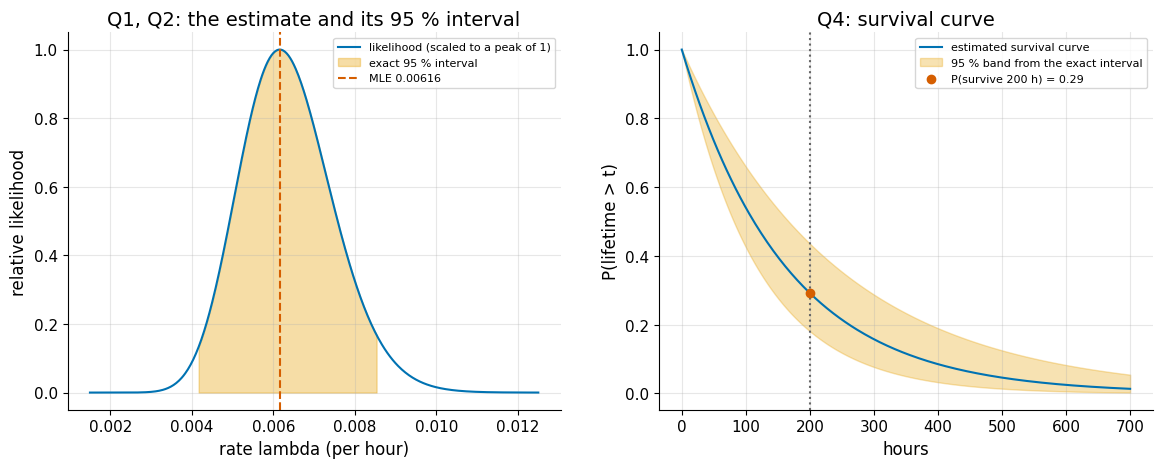

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9))
lg = np.linspace(0.0015, 0.0125, 500)
axes[0].plot(lg, np.exp(30 * np.log(lg) - lg * s_c - (30 * np.log(lg) - lg * s_c).max()), color=MAIN, label="likelihood (scaled to a peak of 1)")
axes[0].fill_between(lg, 0, np.exp(30 * np.log(lg) - lg * s_c - (30 * np.log(lg) - lg * s_c).max()), where=(lg >= exact_c[0]) & (lg <= exact_c[1]), color=SIM, alpha=0.35, label="exact 95 % interval")
axes[0].axvline(lam_c, color=HIGHLIGHT, linestyle="--", label=f"MLE {lam_c:.5f}"); axes[0].set_xlabel("rate lambda (per hour)"); axes[0].set_ylabel("relative likelihood"); axes[0].set_title("Q1, Q2: the estimate and its 95 % interval"); axes[0].legend(fontsize=8)
tt = np.linspace(0, 700, 300)
axes[1].plot(tt, np.exp(-lam_c * tt), color=MAIN, label="estimated survival curve"); axes[1].fill_between(tt, np.exp(-exact_c[1] * tt), np.exp(-exact_c[0] * tt), color=SIM, alpha=0.3, label="95 % band from the exact interval")
axes[1].axvline(200, color=NEUTRAL, linestyle=":"); axes[1].scatter([200], [surv200], color=HIGHLIGHT, zorder=3, label=f"P(survive 200 h) = {surv200:.2f}"); axes[1].set_xlabel("hours"); axes[1].set_ylabel("P(lifetime > t)"); axes[1].set_title("Q4: survival curve"); axes[1].legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The best single estimate of the failure rate is **0.00616 per hour**, i.e. a mean lifetime of **162 hours**. With only 30 components the uncertainty is large: the standard error is 0.00112 (18 % of the estimate) and the exact 95 % interval for the mean lifetime is **117 to 241 hours**.
- **Both intervals work here:** in 100,000 simulated samples of 30 the Wald interval covers the true rate 95.2 % of the time and the exact one 95.0 %. The MLE is slightly biased upward (+3.5 % in the simulation, as the theory $n/(n-1)$ predicts), and the corrected estimate is 0.00595.
- About **29 %** of the components are expected to survive 200 hours (30 % with the corrected rate).
- **Decision.** Plan maintenance for a mean life near 160 h but test the plan against the pessimistic end of the interval (117 h); if the cost of an early failure is high, collect more failure times, since the interval narrows only like $1/\sqrt n$.

---
### Example 2: rainfall amounts: method of moments against maximum likelihood (Gamma)

**Scenario.** Rainfall on rainy days (mm) is modelled as Gamma with unknown shape $k$ and scale $\theta$. A weather office has $n=50$ rainy-day amounts with sample mean **10.2 mm** and sample variance **24.5**.

**Questions**
1. Find the **method-of-moments** estimates $\hat k$ and $\hat\theta$.
2. The maximum-likelihood estimates need numerical work. How do the two estimators compare in **bias and spread** over many repeated samples of 50 days?
3. How much more precise is the MLE of the shape (in terms of the variance ratio)?

### 11.6 By hand
**Q1.** Matching moments: $k\theta=\bar x=10.2$ and $k\theta^2=s^2=24.5$, so $\hat\theta=s^2/\bar x=24.5/10.2=\mathbf{2.40}$ and $\hat k=\bar x^2/s^2=104.04/24.5=\mathbf{4.25}$.

**Q2 and Q3.** The maximum-likelihood equations are $\hat k\hat\theta=\bar x$ and $\ln\hat k-\psi(\hat k)=\ln\bar x-\overline{\ln x}$ (with the digamma function $\psi$), which must be solved numerically. We compare both estimators on 5,000 simulated samples with true $k=2.5$ and $\theta=4$.

In [16]:
k_mom = 10.2 ** 2 / 24.5; th_mom = 24.5 / 10.2
print(f"Q1: method of moments from the summary: shape {k_mom:.3f}, scale {th_mom:.3f}")
k_true, th_true, n_e = 2.5, 4.0, 50
g2 = np.random.default_rng(2); k_mom_s, k_mle_s = [], []
for rep in range(3000):
    x2 = g2.gamma(k_true, th_true, n_e)
    k_mom_s.append(x2.mean() ** 2 / x2.var(ddof=1))
    k_mle_s.append(optimize.brentq(lambda k_: np.log(k_) - special.digamma(k_) - (np.log(x2.mean()) - np.log(x2).mean()), 0.05, 200))
k_mom_s, k_mle_s = np.array(k_mom_s), np.array(k_mle_s)
tab2 = pd.DataFrame({"estimator": ["method of moments", "maximum likelihood"], "mean": [k_mom_s.mean(), k_mle_s.mean()], "bias": [k_mom_s.mean() - k_true, k_mle_s.mean() - k_true], "SD": [k_mom_s.std(), k_mle_s.std()],
                     "RMSE": [np.sqrt(np.mean((k_mom_s - k_true) ** 2)), np.sqrt(np.mean((k_mle_s - k_true) ** 2))]})
print(tab2.round(3).to_string(index=False)); print(f"variance ratio MoM / MLE = {k_mom_s.var() / k_mle_s.var():.2f}")

Q1: method of moments from the summary: shape 4.247, scale 2.402


         estimator  mean  bias    SD  RMSE
 method of moments 2.669 0.169 0.610 0.633
maximum likelihood 2.655 0.155 0.523 0.545
variance ratio MoM / MLE = 1.36


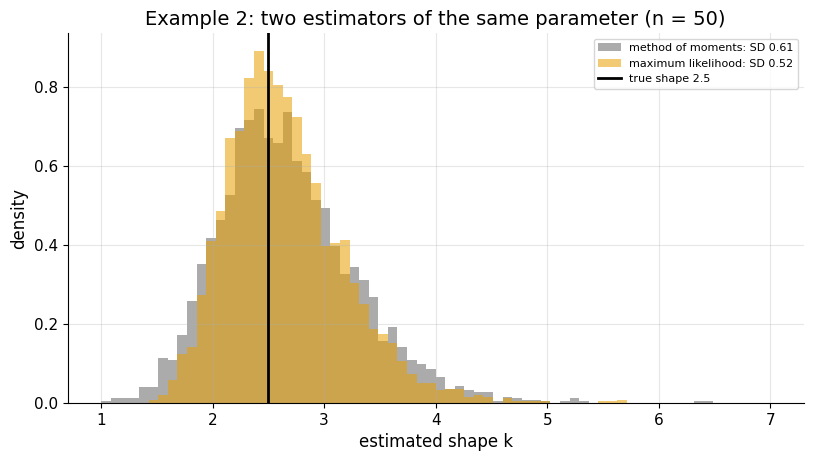

In [17]:
assert abs(k_mom - 4.247) < 0.01 and abs(th_mom - 2.402) < 0.01
assert k_mle_s.std() < k_mom_s.std() and abs(k_mle_s.mean() - k_true) < 0.25
fig, ax = plt.subplots(figsize=(9.5, 4.8))
ax.hist(k_mom_s, bins=70, range=(1, 7), density=True, color=NEUTRAL, alpha=0.55, label=f"method of moments: SD {k_mom_s.std():.2f}"); ax.hist(k_mle_s, bins=70, range=(1, 7), density=True, color=SIM, alpha=0.55, label=f"maximum likelihood: SD {k_mle_s.std():.2f}")
ax.axvline(k_true, color="black", linewidth=2, label="true shape 2.5"); ax.set_xlabel("estimated shape k"); ax.set_ylabel("density"); ax.set_title("Example 2: two estimators of the same parameter (n = 50)"); ax.legend(fontsize=8)
plt.show()

### 11.7 Interpretation and decision (Example 2)
- From the summary numbers the method of moments gives **shape 4.25 and scale 2.40**, a plausible description of the rainfall amounts, but it uses only the first two moments.
- Over 3,000 repeated samples of 50 rainy days the two estimators have similar bias (about +0.16 on a true shape of 2.5) but the **maximum-likelihood estimator is steadier**: SD 0.52 against 0.61 for the moments, a variance ratio of **1.36**. The moments need about **36 % more data** to reach the same precision.
- **Decision.** Use maximum likelihood (`stats.gamma.fit(data, floc=0)`) for the Gamma and keep the moments only as a starting value; report the standard error of the shape, which is large (about 0.5) for 50 observations, before using the fitted tail for flood planning.

---
### Example 3: the German tank problem (a biased MLE that is not Normal)

**Scenario.** Captured tanks carry serial numbers $1,\dots,N$ and **five** captured tanks show the numbers **17, 68, 94, 151, 203**. How many tanks $N$ were produced? Treat the serial numbers as a random sample from $\{1,\dots,N\}$ (modelled here as Uniform$(0,N)$).

**Questions**
1. What are the MLE, the method-of-moments estimate and the unbiased estimate of $N$?
2. Which estimator has the smaller **MSE** if the true $N=250$?
3. Give a 95 % **upper confidence limit** for $N$.

### 11.8 By hand
**Q1.** MLE: the largest serial number, $\hat N_{ML}=\max=\mathbf{203}$ (always too low or equal). MoM: $E[X]=N/2$, so $\hat N_{MoM}=2\bar x=2(106.6)=\mathbf{213.2}$. Unbiased (UMVU): $\max\cdot\frac{n+1}n=203\times1.2=\mathbf{243.6}$ (for the discrete version, $\max+\max/n-1=242.6$).

**Q2.** Computed by simulation below: the MLE is biased low but has the **smallest spread**; the MoM estimate is unbiased but noisy; the rescaled maximum is unbiased with a much smaller variance than the MoM.

**Q3.** $P(\max\le m)=(m/N)^n$, so $P(\max\le203)=(203/N)^5=0.05$ gives $N=203/0.05^{1/5}=203/0.5493=\mathbf{369.6}$: we are 95 % sure that $N\le370$.

In [18]:
tanks = np.array([17, 68, 94, 151, 203]); n_t, mx_t = tanks.size, tanks.max()
est_ml, est_mom, est_unb = mx_t, 2 * tanks.mean(), mx_t * (n_t + 1) / n_t
upper95 = mx_t / 0.05 ** (1 / n_t)
print(f"MLE {est_ml} | method of moments {est_mom:.1f} | unbiased {est_unb:.1f} | 95 % upper limit {upper95:.1f}")
N_true = 250; g3 = np.random.default_rng(3); draws3 = g3.uniform(0, N_true, (200_000, n_t))
ests3 = {"MLE (max)": draws3.max(axis=1), "method of moments (2 xbar)": 2 * draws3.mean(axis=1), "unbiased (max x 6/5)": draws3.max(axis=1) * (n_t + 1) / n_t}
tab3 = pd.DataFrame({k: {"mean": v.mean(), "bias": v.mean() - N_true, "SD": v.std(), "RMSE": np.sqrt(np.mean((v - N_true) ** 2))} for k, v in ests3.items()}).T
print(tab3.round(2).to_string())
cov3 = np.mean(draws3.max(axis=1) / 0.05 ** (1 / n_t) >= N_true); print(f"coverage of the upper limit: {cov3:.4f}")

MLE 203 | method of moments 213.2 | unbiased 243.6 | 95 % upper limit 369.6
                              mean   bias     SD   RMSE
MLE (max)                   208.36 -41.64  35.19  54.52
method of moments (2 xbar)  250.14   0.14  64.55  64.55
unbiased (max x 6/5)        250.03   0.03  42.23  42.23
coverage of the upper limit: 0.9499


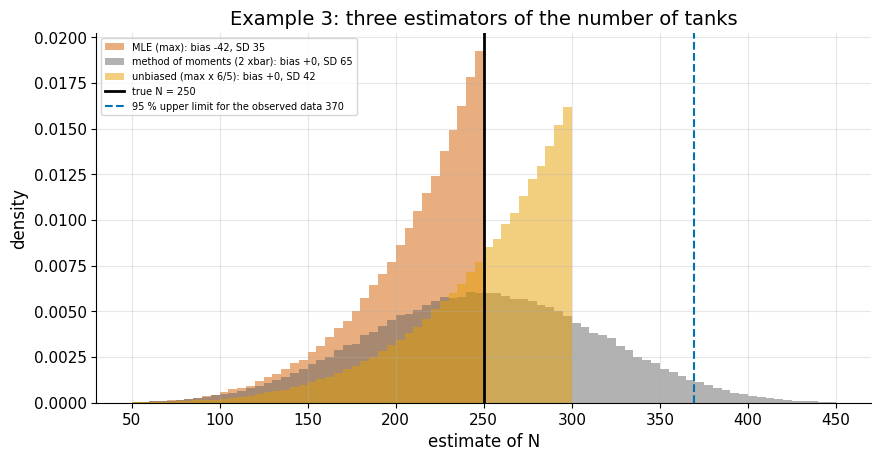

In [19]:
assert est_ml == 203 and abs(est_mom - 213.2) < 0.01 and abs(est_unb - 243.6) < 0.01 and abs(upper95 - 369.6) < 0.2
assert tab3.loc["MLE (max)", "bias"] < -30 and abs(tab3.loc["unbiased (max x 6/5)", "bias"]) < 1.5 and tab3.loc["unbiased (max x 6/5)", "SD"] < tab3.loc["method of moments (2 xbar)", "SD"]
assert abs(cov3 - 0.95) < 0.005
fig, ax = plt.subplots(figsize=(10, 4.8))
for (name, v), c in zip(ests3.items(), [HIGHLIGHT, NEUTRAL, SIM]):
    ax.hist(v, bins=80, range=(50, 450), density=True, color=c, alpha=0.5, label=f"{name}: bias {v.mean() - N_true:+.0f}, SD {v.std():.0f}")
ax.axvline(N_true, color="black", linewidth=2, label="true N = 250"); ax.axvline(upper95, color=MAIN, linestyle="--", label="95 % upper limit for the observed data 370"); ax.set_xlabel("estimate of N"); ax.set_ylabel("density"); ax.set_title("Example 3: three estimators of the number of tanks"); ax.legend(fontsize=7)
plt.show()

### 11.9 Interpretation and decision (Example 3)
- With serial numbers up to 203 among five captured tanks the maximum-likelihood estimate is **203** (a lower bound on $N$), the method of moments gives 213, and the bias-corrected maximum gives **244**. The 95 % upper limit is **370**: we are 95 % sure that no more than about 370 tanks exist.
- Over 200,000 simulated captures of five tanks (true $N=250$): the plain maximum is **biased low by 42** but steady (SD 35); the moments estimate is unbiased but very noisy (SD 65); the corrected maximum is unbiased with the **smallest RMSE (42)**, better than both. The upper limit covers the truth 95.0 % of the time.
- **Decision.** Report the corrected estimate (about 244) together with the interval (203 to 370); never report the raw maximum as the answer. This is a warning that *the MLE is not always the best small-sample estimator*, and that the likelihood can be non-Normal and biased when the range of the data depends on the parameter.

## 12. Where it is used

### Statistics
- **Every parametric model is fitted by maximum likelihood** (regression, GLMs, survival models, time series); standard errors come from the Fisher information, and confidence intervals, likelihood-ratio tests and information criteria (AIC, BIC) are built on it (06_02, 06_03).
- **Method of moments** survives as a fast starting value for numerical fitting (Gamma, Beta, mixtures) and in the generalised method of moments of econometrics.

### Data science
- **Rates and probabilities:** the estimated failure rate, conversion rate or churn rate are MLEs with standard errors $\lambda/\sqrt n$ and $\sqrt{p(1-p)/n}$; planning maintenance or capacity starts here (Example 1).
- **Capture-recapture and "how many are there?" problems** (German tanks, 01_04) are estimation questions where the sampling scheme matters more than the formula.

### ML and AI
- **Training is maximum likelihood:** least squares is the MLE for Normal noise, cross-entropy the MLE for categorical outputs, and the Gaussian-mixture EM of 03_03 maximises a likelihood. Adding a regulariser equals maximum *a posteriori* estimation (Module 07).
- **Fisher information** appears in natural-gradient methods, in the Laplace approximation to Bayesian neural networks and in measuring how sensitive a model is to its parameters.

## 13. Common pitfalls and misconceptions

- **Unbiased does not mean best:** the MSE also includes the variance (Example 3: the biased MLE is more stable than the unbiased MoM).
- **The MLE can be biased** in small samples ($1/\bar x$, the Normal variance) and can be **non-regular** (Uniform maximum), where the usual Normal asymptotics fail.
- **A likelihood is not a probability of the parameter.** It is the probability of the *data* viewed as a function of $\theta$; it does not integrate to 1 over $\theta$ (that needs a prior, Module 07).
- **Wrong model, confident answer:** the MLE of an Exponential rate from data that are really Gamma is still computed, but its standard error is misleading; check the model (Q-Q plot, 05_07).
- **Estimates differ between samples;** the standard error quantifies this. Reporting a bare estimate without its uncertainty invites over-interpretation.
- **Numerical maximisation can fail** (flat ridges, several peaks, boundary solutions): start from the method-of-moments value and compare several starting points.
- **Not every estimator needs the whole sample:** for the Exponential, $\sum x_i$ is *sufficient*: the individual values add nothing (this is why the main example needs only the total).

## 14. Exercises

1. In a survey 7 of 20 customers say they would recommend a product. Find the MLE of the proportion $p$, its standard error and a Wald 95 % interval. Derive the MLE from the log-likelihood $7\ln p+13\ln(1-p)$.
2. Compare the bias and MSE of the two variance estimators $\frac1n\sum(x_i-\bar x)^2$ and $\frac1{n-1}\sum(x_i-\bar x)^2$ for Normal data with $\sigma^2=4$ and $n=5$ by simulation. Which has the smaller MSE?
3. Daily server errors follow a Poisson distribution; the counts over 10 days are 3, 5, 2, 4, 6, 3, 4, 5, 3, 5. Find the MLE of $\lambda$, its Fisher-information standard error, and (by invariance) the MLE of $P(\text{no errors in a day})=e^{-\lambda}$.
4. Show that the Fisher information of a Bernoulli($p$) observation is $1/(p(1-p))$ and find the Cramer-Rao bound for $n=100$ at $p=0.3$. Does $\hat p=\bar x$ attain it?
5. For a Uniform$(a,b)$ distribution find the method-of-moments estimators of $a$ and $b$ from the sample mean 12 and the sample variance 3. Is the result consistent with the sample minimum 9.1 and maximum 15.0?
6. (Harder) For Exponential data show by simulation that the median-based estimator $\tilde\lambda=\ln2/\text{median}$ is less precise than the MLE, and estimate the ratio of the two variances.

Solutions are at the end.

## 15. Summary table

| Idea | Formula | Remember |
|---|---|---|
| MSE | $\mathrm{Var}+\mathrm{Bias}^2$ | accuracy needs both |
| Method of moments | match $E[X^j]$ to $\overline{x^j}$ | quick, sometimes inefficient |
| MLE | $\arg\max\sum\ln f(x_i;\theta)$ | score equation $\ell'=0$ |
| Standard error | $1/\sqrt{nI(\theta)}$ | Exponential rate: $\lambda/\sqrt n$ |
| Cramer-Rao | $\mathrm{Var}\ge1/(nI)$ | MLE attains it asymptotically |
| Invariance | MLE of $g(\theta)$ is $g(\hat\theta)$ | plug in |
| Bias of $1/\bar x$ | $\frac n{n-1}\lambda$ | corrects as $1/n$ |
| Uniform$(0,\theta)$ | MLE $=\max$, biased | rescale by $\frac{n+1}n$ |
| `scipy` | `dist.fit(data)` | `floc=0` to fix the location |

## Solutions

In [20]:
p_hat = 7 / 20; se_p = np.sqrt(p_hat * (1 - p_hat) / 20)
print(f"1: p-hat = {p_hat:.2f} (set 7/p - 13/(1-p) = 0), SE = {se_p:.4f}, Wald interval ({p_hat - 1.96 * se_p:.3f}, {p_hat + 1.96 * se_p:.3f})")
g6 = np.random.default_rng(6); x6 = g6.normal(0, 2, (200_000, 5))
v_n, v_n1 = x6.var(axis=1), x6.var(axis=1, ddof=1)
print(f"2: divide by n: bias {v_n.mean() - 4:+.3f}, MSE {np.mean((v_n - 4) ** 2):.3f} | divide by n-1: bias {v_n1.mean() - 4:+.3f}, MSE {np.mean((v_n1 - 4) ** 2):.3f} -> the biased one has the smaller MSE")
c3 = np.array([3, 5, 2, 4, 6, 3, 4, 5, 3, 5]); lam3 = c3.mean(); print(f"3: lambda-hat = {lam3:.1f}, SE = sqrt(lambda / n) = {np.sqrt(lam3 / 10):.3f}, P(no errors) = exp(-lambda-hat) = {np.exp(-lam3):.4f}")
p4, n4 = 0.3, 100; print(f"4: I(p) = 1 / (p (1 - p)) = {1 / (p4 * (1 - p4)):.3f}, bound = p(1-p)/n = {p4 * (1 - p4) / n4:.5f} = Var(p-hat): attained")
m5, v5 = 12, 3; half = np.sqrt(3 * v5); print(f"5: a = mean - sqrt(3 var) = {m5 - half:.2f}, b = mean + sqrt(3 var) = {m5 + half:.2f}; the observed minimum 9.1 and maximum 15.0 lie inside [{m5 - half:.2f}, {m5 + half:.2f}]: consistent")
e6 = g6.exponential(160, (60_000, 41)); lam_mle = 1 / e6.mean(axis=1); lam_med = np.log(2) / np.median(e6, axis=1)
print(f"6: variance of the median estimator / variance of the MLE = {lam_med.var() / lam_mle.var():.2f}")
assert abs(v_n1.mean() - 4) < 0.03 and np.mean((v_n - 4) ** 2) < np.mean((v_n1 - 4) ** 2) and lam_med.var() > lam_mle.var()

1: p-hat = 0.35 (set 7/p - 13/(1-p) = 0), SE = 0.1067, Wald interval (0.141, 0.559)
2: divide by n: bias -0.801, MSE 5.719 | divide by n-1: bias -0.001, MSE 7.934 -> the biased one has the smaller MSE
3: lambda-hat = 4.0, SE = sqrt(lambda / n) = 0.632, P(no errors) = exp(-lambda-hat) = 0.0183
4: I(p) = 1 / (p (1 - p)) = 4.762, bound = p(1-p)/n = 0.00210 = Var(p-hat): attained
5: a = mean - sqrt(3 var) = 9.00, b = mean + sqrt(3 var) = 15.00; the observed minimum 9.1 and maximum 15.0 lie inside [9.00, 15.00]: consistent
6: variance of the median estimator / variance of the MLE = 2.15


**1.** Setting $\frac7p-\frac{13}{1-p}=0$ gives $\hat p=7/20=\mathbf{0.35}$; $\mathrm{SE}=\sqrt{0.35\times0.65/20}=\mathbf{0.107}$; the Wald 95 % interval is $\mathbf{(0.141,\,0.559)}$: with 20 customers the interval is very wide.

**2.** For $n=5$ and $\sigma^2=4$: dividing by $n$ has bias $-0.80$ and MSE $5.72$; dividing by $n-1$ is unbiased but has MSE $7.93$. The **biased** estimator has the smaller MSE (variance matters more than bias here).

**3.** $\hat\lambda=\bar x=\mathbf{4.0}$ errors per day, $\mathrm{SE}=\sqrt{4/10}=\mathbf{0.632}$, and by invariance $\hat P(\text{no errors})=e^{-4}=\mathbf{0.0183}$ (about 1.8 % of days).

**4.** $I(p)=\dfrac1{p(1-p)}=4.76$ at $p=0.3$; the bound is $\dfrac1{nI}=\dfrac{p(1-p)}n=\mathbf{0.0021}$, exactly the variance of $\hat p=\bar x$: the sample proportion **attains** the bound.

**5.** $\hat a=\bar x-\sqrt{3s^2}=12-3=\mathbf{9.0}$ and $\hat b=12+3=\mathbf{15.0}$. The observed range (9.1 to 15.0) lies inside $[9.0,15.0]$: consistent, with the moments interval hardly wider than the data range.

**6.** The variance of $\ln2/\text{median}$ is about **2.15 times** that of the MLE $1/\bar x$: using the median wastes more than half of the information in the data.